# Реализовать преобразование Хаара (3 ступени сжатия).

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt


def haar_split(block):
    a = block[0::2, 0::2]
    b = block[0::2, 1::2]
    c = block[1::2, 0::2]
    d = block[1::2, 1::2]

    mean = (a + b + c + d) * 0.25
    vert = (a + b - c - d) * 0.25
    horiz = (a - b + c - d) * 0.25
    diag = (a - b - c + d) * 0.25
    return mean, vert, horiz, diag


def show_level(mean, vert, horiz, diag, caption):
    fig, ax = plt.subplots(1, 4, figsize=(15, 4))
    ax[0].imshow(np.abs(mean), cmap='gray');  ax[0].set_title(f'{caption}: среднее')
    ax[1].imshow(np.abs(vert), cmap='gray');  ax[1].set_title(f'{caption}: верт. перепады')
    ax[2].imshow(np.abs(horiz), cmap='gray'); ax[2].set_title(f'{caption}: гор. перепады')
    ax[3].imshow(np.abs(diag), cmap='gray');  ax[3].set_title(f'{caption}: диаг. перепады')
    plt.show()

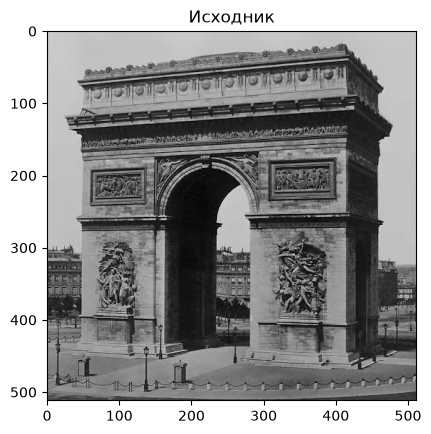

In [5]:
pic = cv.imread('image.jpg', cv.IMREAD_GRAYSCALE)
pic = cv.resize(pic, (512, 512)).astype(np.float32)

plt.imshow(pic, cmap='gray'); plt.title('Исходник'); plt.show()

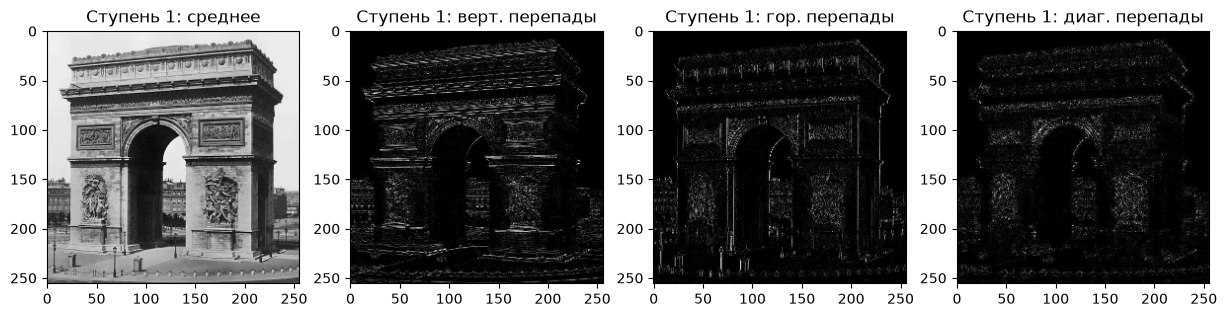

In [6]:
m1, v1, h1, d1 = haar_split(pic)
show_level(m1, v1, h1, d1, 'Ступень 1')

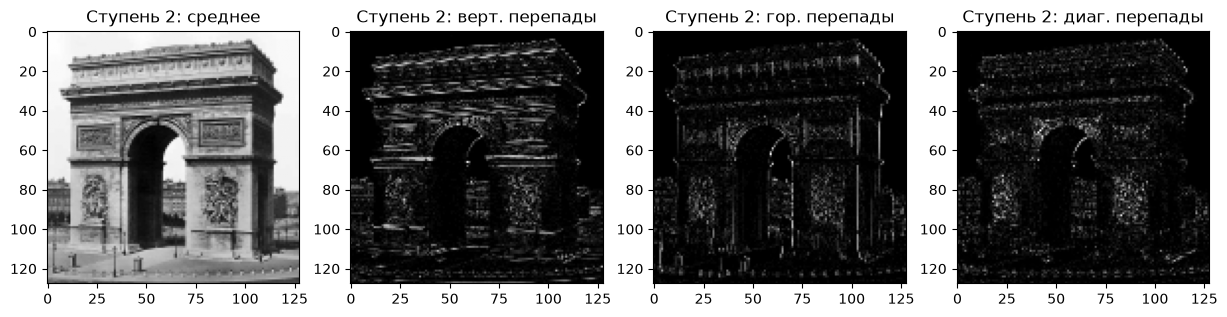

In [7]:
m2, v2, h2, d2 = haar_split(m1)
show_level(m2, v2, h2, d2, 'Ступень 2')

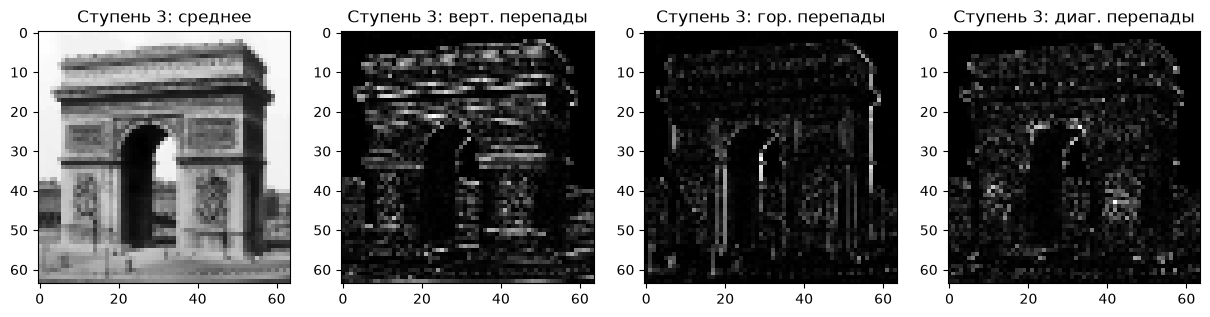

In [8]:
m3, v3, h3, d3 = haar_split(m2)
show_level(m3, v3, h3, d3, 'Ступень 3')